# 02 — Controlled Missing Value Imputation

**HCMUS — Data Mining and Applications.** This chapter implements only the missing-value
comparison in the [official assignment](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/):
mean, median, mode, kNN with k=3/5/10, and MICE. These are **seven configurations in five families**.
The input is [WiDS 2024 Challenge #1](https://www.kaggle.com/competitions/widsdatathon2024-challenge1/data).

## 1. Objective and scientific scope

This is a **retrospective imputation-method benchmark**, reconstructing deliberately hidden,
originally observed numerical measurements. It is not a prospective clinical prediction model.
The completed EDA already examined all labeled rows: every split here is a **post-EDA internal
assessment**, not an untouched external test. No target, ID, ZIP, diagnosis or treatment field
enters an imputer. BMI is documented post-metastatic and remains ineligible for an earlier
baseline unless that prediction question is explicitly changed; benchmarking its reconstruction
does not approve it as a predictor. Natural MCAR/MAR/MNAR remains unidentified.

**Protocol fixed before scoring:** six named numerical variables below; ZIP-disjoint outer 20%
group reserve, inner 25% development-group validation; seeds 42/43; mask seed 2024; floor(10% of
observed validation cells) independently sampled within each feature; same positions for all
methods. All inner-training rows are used, retaining their natural NaNs.

**Primary selection criterion:** lowest macro standardized RMSE, giving each of six features
equal weight and using inner-training SDs only. For MICE, use the mean of this metric over three
posterior completed tables, seeds 101/102/103, ten rounds each. Raw pooled RMSE is reported but
does not select the winner. Exact ties follow the displayed order (simple baselines first).
No seed/subset/criterion is searched after seeing scores. The outer reserve is never scored.

In [1]:
from pathlib import Path
import hashlib
import platform
import sys
from importlib.metadata import version
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn import config_context
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # Enables the documented experimental API.
from sklearn.impute import IterativeImputer

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "myst.yml").is_file() and (p / "src/validate_dataset.py").is_file()), None)
if ROOT is None or Path(sys.prefix) != ROOT / ".venv":
    raise RuntimeError("Start inside the repository and select its .venv kernel (hcmus-wids).")
DATA_PATH = ROOT / "data/raw/training.csv"
ID, TARGET, ZIP = "patient_id", "DiagPeriodL90D", "patient_zip3"
FEATURES = ["patient_age", "bmi", "density", "income_household_median",
            "education_college_or_above", "PM25"]
OUTER_SEED, INNER_SEED, MASK_SEED = 42, 43, 2024
MASK_RATE = 0.10
MICE_SEEDS = [101, 102, 103]
MICE_SETTINGS = dict(sample_posterior=True, max_iter=10, initial_strategy="mean",
                     imputation_order="ascending", n_nearest_features=None,
                     skip_complete=False, keep_empty_features=True)
METHOD_ORDER = ["Mean", "Median", "Mode", "kNN (k=3)", "kNN (k=5)", "kNN (k=10)", "MICE (m=3)"]
KNN_MEMORY_MIB = 128
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140})
print(f"Python {platform.python_version()}; kernel verified: .venv/bin/python")
display(pd.Series({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn"]}, name="version").to_frame())

Python 3.13.3; kernel verified: .venv/bin/python


,version
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1


## 2. Loading, measurement eligibility and grouped separation

The six variables were selected for interpretation and feasibility before scoring: individual
age/BMI, skewed area density, monetary household income, a bounded education proportion, and
annual air-quality context. This covers different scales and heavy BMI missingness without
including entire redundant share blocks. The ranking is **only for these six variables**, not
all 69 numerical candidates. Shared ZIP context and unknown source periods remain limitations.

The source dictionary/timing audit is in [Stage 01](01_eda.ipynb). This chapter preserves the raw
CSV, full frame and reference measurements. Numerical storage does not authorize clinical
codes or ZIPs as continuous measurements. The other numerical columns are excluded for scope,
redundancy risk and compute, not because their imputation scores were unfavorable. Categorical
handling/encoding is outside this numerical RMSE experiment.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("Obtain the official training.csv locally; follow README/Stage 01 preparation.")
raw_sha_before = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH, dtype={ZIP: "string"})
assert df.shape == (12906, 83)
assert df.columns.is_unique and df[ID].notna().all() and df[ID].is_unique
assert df[ZIP].notna().all() and df[TARGET].notna().all() and set(df[TARGET].unique()) == {0, 1}
frame_hash_before = hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()).hexdigest()
dtypes_before, shape_before, columns_before = df.dtypes.copy(), df.shape, df.columns.copy()

clinical_fields = {"breast_cancer_diagnosis_code", "breast_cancer_diagnosis_desc",
                   "metastatic_cancer_diagnosis_code", "metastatic_first_novel_treatment",
                   "metastatic_first_novel_treatment_type"}
forbidden = clinical_fields | {ID, TARGET, ZIP, "patient_state", "Region", "Division",
                               "patient_race", "payer_type", "patient_gender"}
numerical_candidates = [c for c in df.select_dtypes("number") if c not in forbidden]
assert len(numerical_candidates) == 69 and len(FEATURES) == len(set(FEATURES)) == 6
assert set(FEATURES).issubset(numerical_candidates) and set(FEATURES).isdisjoint(forbidden)
assert np.isfinite(df[FEATURES].to_numpy()[df[FEATURES].notna().to_numpy()]).all()
feature_audit = pd.DataFrame({
    "Feature": FEATURES,
    "Role": ["Individual age", "Individual BMI", "Area density", "Area household income",
             "Area percentage", "Annual ZIP3 air concentration"],
    "Observed N (whole file)": df[FEATURES].count().to_numpy(),
    "Missing % (whole file)": df[FEATURES].isna().mean().mul(100).to_numpy(),
    "Timing / interpretation limit": ["Index/baseline alignment unverified", "Documented post-metastatic",
        "Area/reference period unverified", "Area, not personal income; period unverified",
        "Bounded share; period unverified", "Units/year unverified"],
})
display(feature_audit.round(4))
excluded_numeric = [c for c in numerical_candidates if c not in FEATURES]
excluded_categories = [c for c in df if c not in numerical_candidates and c not in {ID, TARGET}]
exclusions = pd.DataFrame([
    {"Group": "ID and target", "N": 2, "Columns": [ID, TARGET], "Reason": "Identification/outcome; never imputation predictors"},
    {"Group": "Categorical/code/text", "N": len(excluded_categories), "Columns": excluded_categories,
     "Reason": "No meaningful continuous RMSE; includes ZIP, diagnosis and treatment"},
    {"Group": "Other numerical candidates", "N": len(excluded_numeric), "Columns": excluded_numeric,
     "Reason": "Compact predeclared benchmark; not a score-based feature selection"},
])
display(HTML("<details><summary>Complete exclusions and reasons</summary>" + exclusions.to_html(index=False) + "</details>"))
print("Input SHA-256:", raw_sha_before)

,Feature,Role,Observed N (whole file),Missing % (whole file),Timing / interpretation limit
0,patient_age,Individual age,12906,0.0000,Index/baseline alignment unverified
1,bmi,Individual BMI,3941,69.4638,Documented post-metastatic
2,density,Area density,12905,0.0077,Area/reference period unverified
3,income_household_median,Area household income,12902,0.0310,"Area, not personal income; period unverified"
4,education_college_or_above,Area percentage,12905,0.0077,Bounded share; period unverified
5,PM25,Annual ZIP3 air concentration,12877,0.2247,Units/year unverified


Group,N,Columns,Reason
ID and target,2,"[patient_id, DiagPeriodL90D]",Identification/outcome; never imputation predictors
Categorical/code/text,12,"[patient_race, payer_type, patient_state, patient_zip3, patient_gender, breast_cancer_diagnosis_code, breast_cancer_diagnosis_desc, metastatic_cancer_diagnosis_code, metastatic_first_novel_treatment, metastatic_first_novel_treatment_type, Region, Division]","No meaningful continuous RMSE; includes ZIP, diagnosis and treatment"
Other numerical candidates,63,"[population, age_median, age_under_10, age_10_to_19, age_20s, age_30s, age_40s, age_50s, age_60s, age_70s, age_over_80, male, female, married, divorced, never_married, widowed, family_size, family_dual_income, income_household_under_5, income_household_5_to_10, income_household_10_to_15, income_household_15_to_20, income_household_20_to_25, income_household_25_to_35, income_household_35_to_50, income_household_50_to_75, income_household_75_to_100, income_household_100_to_150, income_household_150_over, income_household_six_figure, income_individual_median, home_ownership, housing_units, home_value, rent_median, rent_burden, education_less_highschool, education_highschool, education_some_college, education_bachelors, education_graduate, education_stem_degree, labor_force_participation, unemployment_rate, self_employed, farmer, race_white, race_black, race_asian, race_native, race_pacific, race_other, race_multiple, hispanic, disabled, poverty, limited_english, commute_time, health_uninsured, veteran, Ozone, N02]",Compact predeclared benchmark; not a score-based feature selection


Input SHA-256: e9947ecfe1cdacafbf9cbcdc0abd024396f617c701b056fa54e5881f1bb9bbe9


**Split protocol:** `GroupShuffleSplit(test_size=.20, random_state=42)` reserves ZIP groups for
later assessment. Within the remaining development groups, `test_size=.25, random_state=43`
defines imputation validation. Fractions refer to groups, not rows. Target distributions below
are diagnostics only; labels never enter the feature matrices, masks, scaler or imputers.
No stratification/seed search is performed. Both-class support and ID/ZIP separation are checked.

In [3]:
development_pos, reserved_pos = next(GroupShuffleSplit(n_splits=1, test_size=.20, random_state=OUTER_SEED)
                                     .split(df, groups=df[ZIP]))
development_index = df.index[development_pos]
reserved_index = df.index[reserved_pos]
development_groups = df.loc[development_index, ZIP]
train_pos, validation_pos = next(GroupShuffleSplit(n_splits=1, test_size=.25, random_state=INNER_SEED)
                               .split(development_index, groups=development_groups))
train_index, validation_index = development_index[train_pos], development_index[validation_pos]
partitions = {"Inner train": train_index, "Imputation validation": validation_index,
              "Reserved assessment": reserved_index}
split_rows = []
for name, index in partitions.items():
    part = df.loc[index]
    labels = part[TARGET].value_counts().reindex([0, 1], fill_value=0)
    assert (labels > 0).all() and part[ID].is_unique
    split_rows.append({"Partition": name, "Rows": len(index), "ZIP groups": part[ZIP].nunique(),
                       "Class0 N": int(labels.loc[0]), "Class1 N": int(labels.loc[1]),
                       "Class1 %": labels.loc[1] / len(index) * 100})
display(pd.DataFrame(split_rows).round(3))
overlaps = []
names = list(partitions)
for i, left in enumerate(names):
    for right in names[i+1:]:
        a, b = partitions[left], partitions[right]
        counts = {"Row overlap": len(set(a) & set(b)),
                  "ID overlap": len(set(df.loc[a, ID]) & set(df.loc[b, ID])),
                  "ZIP overlap": len(set(df.loc[a, ZIP]) & set(df.loc[b, ZIP]))}
        assert all(v == 0 for v in counts.values())
        overlaps.append({"Pair": f"{left} / {right}", **counts})
display(pd.DataFrame(overlaps))
assert sum(len(i) for i in partitions.values()) == len(df)
X_train = df.loc[train_index, FEATURES].copy(deep=True)
X_validation_reference = df.loc[validation_index, FEATURES].copy(deep=True)
train_hash_before = hashlib.sha256(pd.util.hash_pandas_object(X_train, index=True).to_numpy().tobytes()).hexdigest()
reference_hash_before = hashlib.sha256(pd.util.hash_pandas_object(X_validation_reference, index=True).to_numpy().tobytes()).hexdigest()
assert (X_train.count() >= 2).all() and (X_validation_reference.count() >= 10).all()
assert X_train.index.intersection(reserved_index).empty
distance_mib = len(X_train) * len(X_validation_reference) * np.dtype("float64").itemsize / 1024**2
print(f"Six-column training matrix: {X_train.shape}; validation: {X_validation_reference.shape}.")
print(f"One dense float64 validation×train distance array ≈{distance_mib:.2f} MiB.")
print(f"kNN uses sklearn working_memory={KNN_MEMORY_MIB} MiB for chunking; intermediate allocations can add overhead.")
print("All inner-training rows are used. The reserved partition is never imputed/scored for selection.")
observed_train = X_train.notna().astype(int)
joint_observed = observed_train.T @ observed_train
print(f"Training complete cases: {X_train.dropna().shape[0]}; minimum pairwise observed support: {joint_observed.to_numpy().min()}.")

,Partition,Rows,ZIP groups,Class0 N,Class1 N,Class1 %
0,Inner train,8173,443,3064,5109,62.511
1,Imputation validation,2081,148,778,1303,62.614
2,Reserved assessment,2652,148,1004,1648,62.142


,Pair,Row overlap,ID overlap,ZIP overlap
0,Inner train / Imputation validation,0,0,0
1,Inner train / Reserved assessment,0,0,0
2,Imputation validation / Reserved assessment,0,0,0


Six-column training matrix: (8173, 6); validation: (2081, 6).
One dense float64 validation×train distance array ≈129.76 MiB.
kNN uses sklearn working_memory=128 MiB for chunking; intermediate allocations can add overhead.
All inner-training rows are used. The reserved partition is never imputed/scored for selection.
Training complete cases: 2526; minimum pairwise observed support: 2526.


## 3. Controlled 10% masking and predeclared evaluation

For feature j, let $O_j$ be originally observed validation cells. Uniformly choose
$\lfloor0.10|O_j|\rfloor$ positions without replacement using seed 2024. Sampling is independent
of numerical values and target, conditional on being observed: fixed-count **MCAR by construction
over eligible cells**, not evidence of natural MCAR. Natural NaNs stay NaN. Training retains its
natural missingness; only the validation copy receives artificial gaps. All configurations and
MICE draws use the identical mask and original ground truth.

$$
\operatorname{RMSE}_j=\sqrt{\frac{1}{|M_j|}\sum_{i\in M_j}(x_{ij}-\hat x_{ij})^2},\qquad
\operatorname{RMSE}_{pooled}=\sqrt{\frac{1}{|M|}\sum_{(i,j)\in M}(x_{ij}-\hat x_{ij})^2}.
$$

Raw pooled RMSE mixes units and is income-scale sensitive. For the **primary** equal-feature score:

$$
\operatorname{macroNRMSE}=\frac1p\sum_{j=1}^p\frac{\operatorname{RMSE}_j}{s_{j,train}},\qquad
s_{j,train}=\sqrt{\frac1{n_{j,train}}\sum_{i\in O_{j,train}}(x_{ij}-\bar x_{j,train})^2}.
$$

SD uses ddof 0 and observed training values only (StandardScaler's convention). Unsupported or
zero-SD columns are errors, not silently dropped. For MICE the displayed RMSE/NRMSE is the mean
of three draw-level scores, with sample SD; it is **not** RMSE of averaged imputed values and not
Rubin-rule inferential pooling. Selection never switches to the more favorable secondary metric.
The two small functions below centralize mask/scoring invariants across all seven methods.

In [4]:
def make_mcar_mask(frame, rate=.10, random_state=2024):
    """Uniform fixed-count masking of observed cells, separately per ordered feature."""
    if not 0 < rate < 1 or not frame.index.is_unique or not frame.columns.is_unique:
        raise ValueError("Need unique axes and a masking rate strictly between 0 and 1")
    rng = np.random.default_rng(random_state)
    mask = pd.DataFrame(False, index=frame.index, columns=frame.columns)
    for column in frame:
        eligible = frame.index[frame[column].notna()].to_numpy()
        n_masked = int(np.floor(rate * len(eligible)))
        if n_masked < 1:
            raise ValueError(f"Insufficient observed support for masking: {column}")
        mask.loc[rng.choice(eligible, size=n_masked, replace=False), column] = True
    return mask


def score_masked(reference, completed, mask, train_sd):
    """Score only masked known cells; preserve labels/order and reject invalid predictions."""
    if not (completed.index.equals(reference.index) and mask.index.equals(reference.index)
            and completed.columns.equals(reference.columns) and mask.columns.equals(reference.columns)
            and train_sd.index.equals(reference.columns)):
        raise ValueError("Feature/index alignment mismatch")
    selected = mask.to_numpy(dtype=bool)
    if (selected & reference.isna().to_numpy()).any() or not selected.any():
        raise ValueError("Ground truth must be originally observed masked cells only")
    scale = train_sd.to_numpy(dtype=float)
    if not (np.isfinite(scale).all() and (scale > 0).all()):
        raise ValueError("Training SD must be positive and finite")
    truth, predicted = reference.to_numpy(float), completed.to_numpy(float)
    reconstructed_n = int(np.isfinite(predicted[selected]).sum())
    if reconstructed_n != int(selected.sum()) or not np.isfinite(truth[selected]).all():
        raise ValueError("Invalid ground truth or nonfinite scored prediction")
    residual = predicted - truth
    per_feature = []
    for j, column in enumerate(reference.columns):
        errors = residual[selected[:, j], j]
        if not len(errors):
            raise ValueError(f"No evaluation cells for {column}")
        per_feature.append(float(np.sqrt(np.mean(errors**2))))
    per_feature = pd.Series(per_feature, index=reference.columns, name="RMSE")
    return {"RMSE": float(np.sqrt(np.mean(residual[selected]**2))),
            "Normalized RMSE": float((per_feature / train_sd).mean()),
            "Masked N": int(selected.sum()), "Reconstructed N": reconstructed_n,
            "per_feature": per_feature}

print("Masking and scoring functions defined; independent synthetic checks follow in Section 9.")

Masking and scoring functions defined; independent synthetic checks follow in Section 9.


In [5]:
evaluation_mask = make_mcar_mask(X_validation_reference, MASK_RATE, MASK_SEED)
pd.testing.assert_frame_equal(evaluation_mask, make_mcar_mask(X_validation_reference, MASK_RATE, MASK_SEED))
assert not (evaluation_mask & X_validation_reference.isna()).to_numpy().any()
X_validation_masked = X_validation_reference.mask(evaluation_mask)
pd.testing.assert_frame_equal(X_validation_masked.where(~evaluation_mask),
                              X_validation_reference.where(~evaluation_mask))
assert (X_validation_masked.isna().sum() == X_validation_reference.isna().sum() + evaluation_mask.sum()).all()
mask_hash = hashlib.sha256(pd.util.hash_pandas_object(evaluation_mask, index=True).to_numpy().tobytes()).hexdigest()
mask_audit = pd.DataFrame({"Training observed N": X_train.count(),
                           "Validation observed eligible N": X_validation_reference.count(),
                           "Validation natural NaN N": X_validation_reference.isna().sum(),
                           "Artificial masked N": evaluation_mask.sum()})
mask_audit["Actual masked % of eligible"] = mask_audit["Artificial masked N"] / mask_audit["Validation observed eligible N"] * 100
assert (mask_audit["Artificial masked N"] == np.floor(MASK_RATE * mask_audit["Validation observed eligible N"])).all()
display(mask_audit.round(4))
print("Same evaluation-mask SHA-256 for all configurations:", mask_hash)

# Internal conditioning only; not the separate scaling-comparison rubric.
conditioning_start = perf_counter()
distance_scaler = StandardScaler(copy=True).fit(X_train)
training_sd = X_train.std(ddof=0)
assert (training_sd > 0).all() and np.isfinite(training_sd).all()
np.testing.assert_allclose(distance_scaler.mean_, X_train.mean().to_numpy())
np.testing.assert_allclose(distance_scaler.scale_, training_sd.to_numpy())
np.testing.assert_array_equal(np.broadcast_to(distance_scaler.n_samples_seen_, (len(FEATURES),)), X_train.count().to_numpy())
train_z = pd.DataFrame(distance_scaler.transform(X_train), index=X_train.index, columns=FEATURES)
validation_z = pd.DataFrame(distance_scaler.transform(X_validation_masked), index=X_validation_masked.index, columns=FEATURES)
np.testing.assert_allclose(distance_scaler.inverse_transform(validation_z), X_validation_masked.to_numpy(), equal_nan=True)
conditioning_seconds = perf_counter() - conditioning_start
display(pd.DataFrame({"Train mean": distance_scaler.mean_, "Train SD (ddof 0)": training_sd}, index=FEATURES))
print(f"Shared train-only conditioning: {conditioning_seconds:.4f}s (separate from each method's fit+transform time).")

,Training observed N,Validation observed eligible N,Validation natural NaN N,Artificial masked N,Actual masked % of eligible
patient_age,8173,2081,0,208,9.9952
bmi,2531,639,1442,63,9.8592
density,8173,2080,1,208,10.0000
income_household_median,8173,2077,4,207,9.9663
education_college_or_above,8173,2080,1,208,10.0000
PM25,8148,2079,2,207,9.9567


Same evaluation-mask SHA-256 for all configurations: d4e1ced320653122022edadea5bac1d443271af2fccfdd26efb7db5842c8e22e


,Train mean,Train SD (ddof 0)
patient_age,59.100575,13.258839
bmi,28.888163,5.797514
density,1336.089690,1894.117454
income_household_median,75295.676119,18697.794288
education_college_or_above,31.803267,10.909926
PM25,7.530382,1.533624


Shared train-only conditioning: 0.0056s (separate from each method's fit+transform time).


## 4. Mean, Median and Mode baselines

SimpleImputer learns one statistic from each column's **observed inner-training values**:

$$
\hat x_{ij}^{mean}=\bar x_{j,train},\qquad
\hat x_{ij}^{median}=\operatorname{median}(X_{j,train}^{obs}),\qquad
\hat x_{ij}^{mode}=\operatorname{mode}(X_{j,train}^{obs}).
$$

Mean is sensitive to tails; median is relatively robust. Mode is included as a **numerical**
baseline required by the rubric: sklearn chooses the smallest value when counts tie. For
continuous measurements it depends on precision/ties and is not a conditional predictor.
Categorical mode could be evaluated with classification-style measures separately; categorical
codes are not given numerical RMSE here. All three operate in original units with no validation fit.

In [6]:
evaluation_rows, per_feature_scores, completed_values, fitted_imputers = [], {}, {}, {}
fit_rows, mask_hashes = {}, {}
for method, strategy in [("Mean", "mean"), ("Median", "median"), ("Mode", "most_frequent")]:
    start = perf_counter()
    imputer = SimpleImputer(strategy=strategy, copy=True, keep_empty_features=True).fit(X_train)
    completed = pd.DataFrame(imputer.transform(X_validation_masked), index=validation_index, columns=FEATURES)
    elapsed = perf_counter() - start
    np.testing.assert_array_equal(imputer.feature_names_in_, FEATURES)
    if strategy == "mean":
        np.testing.assert_allclose(imputer.statistics_, X_train.mean().to_numpy())
    elif strategy == "median":
        np.testing.assert_allclose(imputer.statistics_, X_train.median().to_numpy())
    else:
        expected_modes = X_train.mode(dropna=True).iloc[0].to_numpy()
        np.testing.assert_allclose(imputer.statistics_, expected_modes)
    score = score_masked(X_validation_reference, completed, evaluation_mask, training_sd)
    evaluation_rows.append({"Method": method, "Parameters": f"strategy={strategy}; training-only",
                            **{k: score[k] for k in ["Masked N", "Reconstructed N", "RMSE", "Normalized RMSE"]},
                            "RMSE draw SD": 0., "Normalized draw SD": 0., "Draws": 1,
                            "Runtime (s)": elapsed, "Status": "PASS"})
    per_feature_scores[method] = score["per_feature"]
    completed_values[method], fitted_imputers[method] = [completed], [imputer]
    fit_rows[method], mask_hashes[method] = len(X_train), mask_hash
display(pd.DataFrame(evaluation_rows)[["Method", "RMSE", "Normalized RMSE", "Runtime (s)"]].round(5))
mode_audit = pd.DataFrame({"Training mode": fitted_imputers["Mode"][0].statistics_,
    "Tied modal values N": [int((X_train[c].value_counts() == X_train[c].value_counts().max()).sum()) for c in FEATURES]}, index=FEATURES)
display(mode_audit)

,Method,RMSE,Normalized RMSE,Runtime (s)
0,Mean,10781.65647,1.08081,0.00157
1,Median,10811.53806,1.09145,0.00372
2,Mode,11130.57141,1.65760,0.00361


,Training mode,Tied modal values N
patient_age,63.000000,1
bmi,27.000000,1
density,5294.330882,1
income_household_median,69266.693550,1
education_college_or_above,37.575385,1
PM25,11.166898,1


The numerical outputs above measure reconstruction, not downstream prediction. Each baseline
replaces a missing column entry with a single training statistic; it cannot exploit another
feature's information. Inspect modal ties rather than assuming that a numerical mode is stable.
The final comparison keeps these baselines even if a more complex method scores better.

## 5. kNN: k=3,5,10 with train-fitted distance conditioning

For jointly observed coordinates $A_{ir}$ among p standardized features, sklearn's missing-aware
Euclidean distance is

$$
d(i,r)=\sqrt{\frac{p}{|A_{ir}|}\sum_{j\in A_{ir}}(z_{ij}-z_{rj})^2}.
$$

For each missing feature, neighbors must have that value observed in the training data;
`weights="uniform"` averages available donor values. If fewer donors are available, sklearn
uses those available; if usable distances cannot be defined, its training-column-mean fallback
applies. No validation row becomes a fitted donor. Small k can be locally flexible/noisy;
larger k trades locality for smoothing. Few common coordinates can make distances less informative.

StandardScaler ignores training NaNs when learning mean/SD and preserves NaNs during transform.
We scale with **training** statistics and inverse-transform completions before raw-unit scoring.
This avoids silently measuring income in much larger units than age/air concentration; it is
internal conditioning, not completion of the separate scaler-comparison assignment.
See the [installed-API reference](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html).

In [7]:
for k in [3, 5, 10]:
    method = f"kNN (k={k})"
    start = perf_counter()
    imputer = KNNImputer(n_neighbors=k, weights="uniform", metric="nan_euclidean",
                         copy=True, keep_empty_features=True).fit(train_z)
    with config_context(working_memory=KNN_MEMORY_MIB):
        filled_z = imputer.transform(validation_z)
    completed = pd.DataFrame(distance_scaler.inverse_transform(filled_z), index=validation_index, columns=FEATURES)
    elapsed = perf_counter() - start
    np.testing.assert_array_equal(imputer.feature_names_in_, FEATURES)
    np.testing.assert_allclose(completed.to_numpy()[~X_validation_masked.isna().to_numpy()],
                               X_validation_masked.to_numpy()[~X_validation_masked.isna().to_numpy()])
    score = score_masked(X_validation_reference, completed, evaluation_mask, training_sd)
    evaluation_rows.append({"Method": method, "Parameters": f"k={k}; uniform; nan_euclidean; train-SD conditioning",
                            **{key: score[key] for key in ["Masked N", "Reconstructed N", "RMSE", "Normalized RMSE"]},
                            "RMSE draw SD": 0., "Normalized draw SD": 0., "Draws": 1,
                            "Runtime (s)": elapsed, "Status": "PASS"})
    per_feature_scores[method] = score["per_feature"]
    completed_values[method], fitted_imputers[method] = [completed], [imputer]
    fit_rows[method], mask_hashes[method] = len(X_train), mask_hash
display(pd.DataFrame(evaluation_rows).set_index("Method").loc[METHOD_ORDER[3:6], ["RMSE", "Normalized RMSE", "Runtime (s)"]].round(5))

,RMSE,Normalized RMSE,Runtime (s)
Method,,,
kNN (k=3),7380.06385,1.00923,0.37511
kNN (k=5),7175.30820,0.96711,0.35101
kNN (k=10),7297.48306,0.95477,0.36321


Compare the three k values on the same masked cells, not different samples. The benchmark uses
all inner-training donors and six fixed features. There is no unscaled-kNN arm, so a numerical
benefit from scaling cannot be estimated by this experiment; the train SDs explain why unit
conditioning was specified. ZIP-disjoint evaluation limits direct shared-ZIP donor leakage,
while repeated validation context still makes the patient-weighted errors dependent.

## 6. MICE: three posterior chained-equation completions

IterativeImputer initializes missing entries, then models each feature from the other features
in repeated rounds. We use its default BayesianRidge conditional estimator and
`sample_posterior=True`, drawing from its Gaussian predictive posterior rather than returning
one deterministic conditional mean:

$$
x_{ij}^{(t,\ell)}\sim p(x_{ij}\mid x_{i,-j}^{(t,\ell)},\,X_{train}^{obs},\,\theta_j^{(t,\ell)}).
$$

Use m=3 distinct fixed seeds and ten rounds, all six predictors (`n_nearest_features=None`).
`skip_complete=False` matters: even a feature complete during fitting must have a conditional
model when validation masking creates new gaps. In posterior mode sklearn does **not** apply
its deterministic early-stopping criterion; ten rounds is a budget, not proof of convergence.
Each draw is fitted on training only and transformed once for scoring. Repeated calls to a
posterior imputer's transform advance its RNG; stored completions are reused for all metrics.

Multiple completed tables are retained in memory. Primary scores are averaged **across draw
metrics**, with sample SD, not averaged imputations. No Rubin-rule inferential pooling is claimed.
Linear/Gaussian conditional models and unbounded draws may be unsuitable for bounded/skewed
features; natural MAR is not established. Read the installed sklearn 1.9.1 docstring and
[IterativeImputer documentation](https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html).

In [8]:
mice_completions, mice_models, mice_draw_rows = [], [], []
# pandas 3 may expose read-only arrays; sklearn iterative initialization needs writable copies.
assert train_z.columns.equals(pd.Index(FEATURES)) and validation_z.columns.equals(train_z.columns)
for seed in MICE_SEEDS:
    start = perf_counter()
    imputer = IterativeImputer(**MICE_SETTINGS, random_state=seed).fit(train_z.to_numpy(copy=True))
    filled_z = imputer.transform(validation_z.to_numpy(copy=True))
    completed = pd.DataFrame(distance_scaler.inverse_transform(filled_z), index=validation_index, columns=FEATURES)
    elapsed = perf_counter() - start
    assert imputer.n_features_in_ == len(FEATURES)
    np.testing.assert_allclose(imputer.initial_imputer_.statistics_, train_z.mean().to_numpy(), atol=1e-12)
    assert imputer.n_iter_ == MICE_SETTINGS["max_iter"]
    score = score_masked(X_validation_reference, completed, evaluation_mask, training_sd)
    mice_draw_rows.append({"Seed": seed, "Rounds": imputer.n_iter_, "RMSE": score["RMSE"],
                           "Normalized RMSE": score["Normalized RMSE"], "Masked N": score["Masked N"],
                           "Reconstructed N": score["Reconstructed N"], "Runtime (s)": elapsed})
    mice_completions.append(completed)
    mice_models.append(imputer)
mice_draw_results = pd.DataFrame(mice_draw_rows).set_index("Seed")
assert mice_draw_results["Masked N"].nunique() == mice_draw_results["Reconstructed N"].nunique() == 1
assert not np.array_equal(mice_completions[0].to_numpy()[evaluation_mask.to_numpy()],
                          mice_completions[1].to_numpy()[evaluation_mask.to_numpy()])
method = METHOD_ORDER[-1]
evaluation_rows.append({"Method": method,
    "Parameters": f"BayesianRidge; posterior=True; m=3; rounds=10; seeds={MICE_SEEDS}; skip_complete=False",
    "Masked N": int(evaluation_mask.to_numpy().sum()),
    "Reconstructed N": int(mice_draw_results["Reconstructed N"].iloc[0]),
    "RMSE": mice_draw_results.RMSE.mean(), "Normalized RMSE": mice_draw_results["Normalized RMSE"].mean(),
    "RMSE draw SD": mice_draw_results.RMSE.std(ddof=1),
    "Normalized draw SD": mice_draw_results["Normalized RMSE"].std(ddof=1),
    "Draws": len(MICE_SEEDS), "Runtime (s)": mice_draw_results["Runtime (s)"].sum(), "Status": "PASS"})
per_feature_scores[method] = pd.concat([
    score_masked(X_validation_reference, completed, evaluation_mask, training_sd)["per_feature"]
    for completed in mice_completions], axis=1).mean(axis=1)
completed_values[method], fitted_imputers[method] = mice_completions, mice_models
fit_rows[method], mask_hashes[method] = len(X_train), mask_hash
display(mice_draw_results.round(5))

,Rounds,RMSE,Normalized RMSE,Masked N,Reconstructed N,Runtime (s)
Seed,,,,,,
101,10,8459.84534,1.19215,1101,1101,0.14438
102,10,8703.75867,1.20578,1101,1101,0.13424
103,10,8739.82490,1.22881,1101,1101,0.13476


Variation above is between posterior completions of the same split/mask; it is neither a
confidence interval nor split/mask/geographic sampling variability. The single MICE comparison
row below uses the predeclared mean scores, with all three completions successfully reconstructed
at identical positions. A low artificial-mask score would not validate imputations of natural
NaNs, model assumptions, clinical plausibility or future feature eligibility.

## 7. Fair comparison and declared selection

All seven rows use the same six features and unique masked positions. Masked/Reconstructed N
are **per completed table**; MICE has three tables, not three times as many evaluation cells.
Raw pooled RMSE remains required evidence, but sums squared quantities with different units.
Normalized RMSE is the equal-feature mean of per-feature RMSE divided by training SD. For MICE,
both the aggregate and per-feature cells are means of draw-level RMSEs; they are not errors of
an averaged point estimate. Runtime is fit+transform (all three draws for MICE), excluding the
separately reported shared conditioning and correctness verification. Hardware/timing noise is
not a method-quality metric. The fixed criterion and displayed-order tie break determine the winner.

,Parameters,Masked N,Reconstructed N,RMSE,Normalized RMSE,Runtime (s),Status
Method,,,,,,,
Mean,train mean,1101,1101,10781.6565,1.08081,0.0016,PASS
Median,train median,1101,1101,10811.5381,1.09145,0.0037,PASS
Mode,train mode,1101,1101,11130.5714,1.65760,0.0036,PASS
kNN (k=3),k=3; uniform; z,1101,1101,7380.0639,1.00923,0.3751,PASS
kNN (k=5),k=5; uniform; z,1101,1101,7175.3082,0.96711,0.3510,PASS
kNN (k=10),k=10; uniform; z,1101,1101,7297.4831,0.95477,0.3632,PASS
MICE (m=3),m=3; posterior; 10 rounds,1101,1101,8634.4763,1.20891,0.4134,PASS


,Mean,Median,Mode,kNN 3,kNN 5,kNN 10,MICE 3
Feature (original units),,,,,,,
Age,13.484,13.467,14.678,18.074,16.465,15.766,18.988
BMI,4.918,5.048,5.369,5.901,5.449,5.236,7.522
Density,1569.799,1600.028,4460.508,1509.941,1480.763,1509.985,2123.440
Median household income,24815.466,24882.584,25277.587,16952.909,16481.419,16761.688,19799.130
College-or-above share,14.348,14.384,15.527,8.250,8.052,7.910,10.040
PM25,1.761,1.792,4.267,1.862,1.870,1.868,2.183


,Lowest per-feature RMSE configuration
Feature (original units),
patient_age,Median
bmi,Mean
density,kNN (k=5)
income_household_median,kNN (k=5)
education_college_or_above,kNN (k=10)
PM25,Mean


,Mean,Median,Mode,kNN (k=3),kNN (k=5),kNN (k=10),MICE (m=3)
Feature (original units),,,,,,,
patient_age,1.01699,1.01569,1.10701,1.36319,1.24183,1.18910,1.43209
bmi,0.84833,0.87071,0.92608,1.01783,0.93994,0.90306,1.29752
density,0.82878,0.84474,2.35493,0.79717,0.78177,0.79720,1.12107
income_household_median,1.32719,1.33078,1.35190,0.90668,0.88146,0.89645,1.05890
education_college_or_above,1.31512,1.31845,1.42316,0.75618,0.73803,0.72504,0.92026
PM25,1.14848,1.16835,2.78255,1.21435,1.21963,1.21778,1.42363


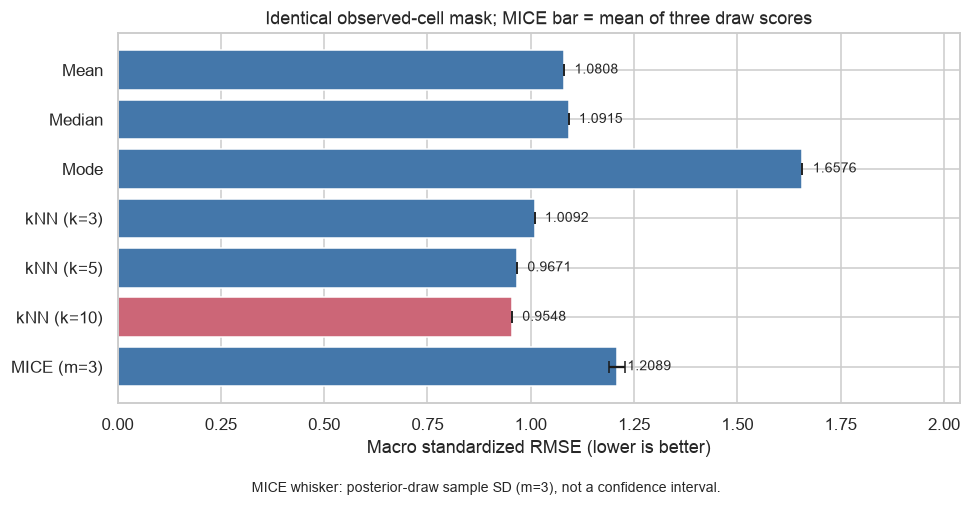

In [9]:
comparison = pd.DataFrame(evaluation_rows).set_index("Method").loc[METHOD_ORDER]
assert len(comparison) == 7 and comparison.Status.eq("PASS").all()
assert comparison["Masked N"].eq(evaluation_mask.to_numpy().sum()).all()
assert comparison["Reconstructed N"].equals(comparison["Masked N"])
assert np.isfinite(comparison[["RMSE", "Normalized RMSE", "Runtime (s)"]]).all().all()
winner = comparison["Normalized RMSE"].sort_values(kind="stable").index[0]
# Short labels keep the book table readable; full settings are defined above and retained in comparison.
comparison_display = comparison[["Parameters", "Masked N", "Reconstructed N", "RMSE", "Normalized RMSE", "Runtime (s)", "Status"]].copy()
comparison_display["Parameters"] = ["train mean", "train median", "train mode", "k=3; uniform; z", "k=5; uniform; z", "k=10; uniform; z", "m=3; posterior; 10 rounds"]
display(HTML('<div style="overflow-x:auto;max-width:100%">' + comparison_display.to_html(
    formatters={"RMSE": "{:.4f}".format, "Normalized RMSE": "{:.5f}".format, "Runtime (s)": "{:.4f}".format}) + '</div>'))
per_feature_rmse = pd.DataFrame(per_feature_scores).loc[FEATURES, METHOD_ORDER]
per_feature_rmse.index.name = "Feature (original units)"
# Only display labels are shortened; per_feature_rmse retains the original schema and full precision.
per_feature_display = per_feature_rmse.rename(index={
    "patient_age": "Age", "bmi": "BMI", "density": "Density",
    "income_household_median": "Median household income",
    "education_college_or_above": "College-or-above share"},
    columns={"kNN (k=3)": "kNN 3", "kNN (k=5)": "kNN 5", "kNN (k=10)": "kNN 10", "MICE (m=3)": "MICE 3"})
per_feature_display.index.name = "Feature (original units)"
display(HTML('<div style="overflow-x:auto;max-width:100%">' + per_feature_display.to_html(float_format="{:.3f}".format) + '</div>'))
feature_winners = per_feature_rmse.idxmin(axis=1)
display(feature_winners.rename("Lowest per-feature RMSE configuration").to_frame())
per_feature_normalized = per_feature_rmse.div(training_sd, axis="index")
display(HTML("<details><summary>Per-feature RMSE / training SD (dimensionless)</summary>"
             + per_feature_normalized.round(5).to_html() + "</details>"))

fig, ax = plt.subplots(figsize=(9, 4.6))
colors = ["#CC6677" if method == winner else "#4477AA" for method in METHOD_ORDER]
ax.barh(METHOD_ORDER, comparison["Normalized RMSE"],
        xerr=comparison["Normalized draw SD"], color=colors, capsize=4)
ax.invert_yaxis()
ax.set(xlabel="Macro standardized RMSE (lower is better)",
       title="Identical observed-cell mask; MICE bar = mean of three draw scores")
for y, value in enumerate(comparison["Normalized RMSE"]):
    ax.text(value + comparison["Normalized RMSE"].max()*.015, y, f"{value:.4f}", va="center", fontsize=9)
ax.set_xlim(0, (comparison["Normalized RMSE"] + comparison["Normalized draw SD"]).max()*1.23)
fig.text(.5, .01, "MICE whisker: posterior-draw sample SD (m=3), not a confidence interval.", ha="center", fontsize=9)
plt.tight_layout(rect=(0, .04, 1, 1)); plt.show()

## 8. Selection, interpretation and handoff

The following interpretation is calculated from the results, not filled with anticipated numbers.
The overall winner, per-feature winners and a later predictive-pipeline decision are distinct.
Selection here does not authorize deployment, target-dependent imputation or use of the reserve.

In [10]:
simple_best = comparison.loc[METHOD_ORDER[:3], "Normalized RMSE"].idxmin()
knn_best = comparison.loc[METHOD_ORDER[3:6], "Normalized RMSE"].idxmin()
raw_winner = comparison.RMSE.sort_values(kind="stable").index[0]
mice_score = comparison.loc["MICE (m=3)", "Normalized RMSE"]
relative_to_simple = (comparison.loc[simple_best, "Normalized RMSE"] - mice_score) / comparison.loc[simple_best, "Normalized RMSE"] * 100
scale_ratio = training_sd.max() / training_sd.min()
display(HTML(
    f"<p><strong>Observed benchmark result:</strong> all {len(comparison)} configurations completed. "
    f"The predeclared primary winner is <strong>{winner}</strong>, macro standardized RMSE="
    f"{comparison.loc[winner, 'Normalized RMSE']:.5f}; its raw pooled RMSE="
    f"{comparison.loc[winner, 'RMSE']:.4f}. All use {int(evaluation_mask.to_numpy().sum())} identical known-cell positions.</p>"
    f"<p>The best simple baseline is {simple_best} ({comparison.loc[simple_best, 'Normalized RMSE']:.5f}); "
    f"the best kNN setting is {knn_best} ({comparison.loc[knn_best, 'Normalized RMSE']:.5f}). "
    f"MICE has mean={mice_score:.5f}, draw SD={comparison.loc['MICE (m=3)', 'Normalized draw SD']:.5f}, "
    f"total fit+transform={comparison.loc['MICE (m=3)', 'Runtime (s)']:.3f}s; its relative primary-score "
    f"reduction versus the best simple baseline is {relative_to_simple:+.2f}% (negative means worse). "
    "This numerical comparison, model assumptions and computational cost determine whether its complexity is worthwhile here.</p>"
    f"<p>Raw pooled RMSE ranks {raw_winner} first. "
    + ("This agrees with the primary winner." if raw_winner == winner else "This conflicts with the primary winner; the declared normalized criterion is retained.")
    + f" Training SDs span a ratio of {scale_ratio:.1f}, explaining the unit-conditioning design; "
    "without an unscaled arm, its effect on kNN error is not identified. Per-feature winners are reported separately, not substituted after selection.</p>"
))
primary_gain = (1 - comparison.loc[winner, "Normalized RMSE"] / comparison.loc[simple_best, "Normalized RMSE"]) * 100
mice_assessment = (
    "Its lower primary score supports considering the added modeling effort in this benchmark."
    if mice_score < comparison.loc[simple_best, "Normalized RMSE"]
    else "It does not improve the primary score over the best simple baseline, so its added modeling effort is not justified for this point-reconstruction choice."
)
display(HTML(
    f"<p>The selected {winner} reduces the primary score by {primary_gain:.2f}% versus {simple_best}. "
    f"Feature-level minima are age: {feature_winners['patient_age']}; BMI: {feature_winners['bmi']}; "
    f"density/income: {feature_winners['density']} / {feature_winners['income_household_median']}; "
    f"education: {feature_winners['education_college_or_above']}; PM25: {feature_winners['PM25']}. "
    "The context-variable gains and competitive individual-variable baselines show why one aggregate ranking cannot dictate every feature's treatment.</p>"
    f"<p><strong>MICE decision:</strong> {mice_assessment} "
    "Posterior draws retain uncertainty and can increase squared reconstruction error relative to a conditional mean; "
    "this loss does not assess the inferential value of multiple imputation. Conditional-model mismatch and weak predictive "
    "information are possible explanations, not separately tested causes. Mean is a cheap, competitive fallback; "
    "numerical Mode cannot be assumed useful merely because it is common for categories.</p>"
))


**Limits and next-stage decisions.** This single ZIP-disjoint split and one artificial mask do
not establish a universal ranking or uncertainty across populations/masks. The observed subset
used as ground truth may differ systematically from natural missing cases, especially BMI;
natural missingness is not classified by these RMSEs. Validation remains patient-weighted with
shared area values, and geographically disjoint groups can still be spatially dependent.
The Gaussian chained-equation models/posterior variance and three-draw budget constrain MICE;
unbounded imputations need domain review before future use, and no clipping/treatment is applied.

The benchmark's internal StandardScaler does not complete the later scaling-comparison rubric.
Carry the selected configuration forward as a **candidate**, freeze its role and compare it only
within development folds in later experiments. Keep BMI and treatment out of any earlier-baseline
predictor set unless availability is justified; do not silently treat the six benchmark columns
as a clinically eligible feature list. The outer assessment is still reserved against further
fitting/tuning, with its prior EDA exposure disclosed. No classifier, resampling, encoding,
outlier treatment or feature-selection experiment is implemented here.

## 9. Focused correctness checks and data integrity

Small fixtures below test masking/scoring independently of the real-data ranking. A separate
real first-seed MICE refit verifies reproducibility without changing the three scored draws.
Validation/refit time is not part of the method runtime table. No patient rows are exported.

In [11]:
checks = {}
fixture = pd.DataFrame({"a": np.arange(30, dtype=float), "b": 3*np.arange(30, dtype=float)+1})
fixture.loc[::11, "a"] = np.nan
fixture.loc[::13, "b"] = np.nan
fixture_before = fixture.copy(deep=True)
fixture_mask = make_mcar_mask(fixture, .10, 71)
pd.testing.assert_frame_equal(fixture_mask, make_mcar_mask(fixture, .10, 71))
pd.testing.assert_frame_equal(fixture_mask, make_mcar_mask(fixture+1000, .10, 71))
assert not (fixture_mask & fixture.isna()).to_numpy().any()
np.testing.assert_array_equal(fixture_mask.sum(), np.floor(fixture.count()*.10))
pd.testing.assert_frame_equal(fixture, fixture_before)
checks["Mask reproducibility / exact floor count / no natural-NaN ground truth / no mutation"] = True

# Unmasked errors and natural NaNs must not contribute to the score.
probe = fixture + 10000
probe = probe.mask(fixture_mask, fixture)
unit_sd = pd.Series(1., index=fixture.columns)
assert score_masked(fixture, probe, fixture_mask, unit_sd)["RMSE"] == 0
probe = probe.mask(fixture_mask, fixture+2)
assert score_masked(fixture, probe, fixture_mask, unit_sd)["RMSE"] == 2
checks["RMSE uses masked known cells only; analytic RMSE matches"] = True
bad = probe.copy(); i,j = np.argwhere(fixture_mask.to_numpy())[0]; bad.iloc[i,j] = np.nan
try:
    score_masked(fixture, bad, fixture_mask, unit_sd)
except ValueError:
    checks["Nonfinite scored prediction rejected"] = True
else:
    raise AssertionError("Invalid prediction was accepted")
bad_mask = fixture_mask.copy(); i,j = np.argwhere(fixture.isna().to_numpy())[0]; bad_mask.iloc[i,j] = True
try:
    score_masked(fixture, probe, bad_mask, unit_sd)
except ValueError:
    checks["Natural-NaN ground truth rejected"] = True
else:
    raise AssertionError("Natural missing value was scored")

small_train = pd.DataFrame({"a": [0., 2., 4., np.nan], "b": [10., 10., 20., 30.]})
small_validation = pd.DataFrame({"a": [1000., np.nan], "b": [np.nan, 999.]})
small_mean = SimpleImputer(strategy="mean").fit(small_train)
np.testing.assert_allclose(small_mean.statistics_, [2., 17.5])
small_completed = small_mean.transform(small_validation)
np.testing.assert_allclose(small_completed, [[1000., 17.5], [2., 999.]])
small_scaler = StandardScaler().fit(small_train)
np.testing.assert_allclose(small_scaler.mean_, [2., 17.5])
np.testing.assert_allclose(small_scaler.inverse_transform(small_scaler.transform(small_validation)), small_validation, equal_nan=True)
assert SimpleImputer(strategy="most_frequent").fit(pd.DataFrame({"a": [1., 1., 2., 2.]})).statistics_[0] == 1
checks["Train-only statistics / validation separation / inverse units / smallest-mode tie"] = True

rng = np.random.default_rng(19)
small_chain_train = pd.DataFrame(rng.normal(size=(40, 3)), columns=["a", "b", "c"])
small_chain_train.loc[::4, "b"] = np.nan
small_chain_validation = pd.DataFrame(rng.normal(size=(20, 3)), columns=small_chain_train.columns)
small_chain_validation.loc[::3, "a"] = np.nan
small_draws = []
for _ in range(2):
    small_model = IterativeImputer(sample_posterior=True, max_iter=3, skip_complete=False, random_state=101).fit(small_chain_train.to_numpy(copy=True))
    small_draws.append(small_model.transform(small_chain_validation.to_numpy(copy=True)))
np.testing.assert_array_equal(small_draws[0], small_draws[1])
assert np.isfinite(small_draws[0]).all()
checks["Posterior MICE fixed-seed reproducibility on synthetic data"] = True
display(pd.Series(checks, name="PASS").to_frame())
assert all(checks.values())

,PASS
Mask reproducibility / exact floor count / no natural-NaN ground truth / no mutation,True
RMSE uses masked known cells only; analytic RMSE matches,True
Nonfinite scored prediction rejected,True
Natural-NaN ground truth rejected,True
Train-only statistics / validation separation / inverse units / smallest-mode tie,True
Posterior MICE fixed-seed reproducibility on synthetic data,True


In [12]:
repeat_model = IterativeImputer(**MICE_SETTINGS, random_state=MICE_SEEDS[0]).fit(train_z.to_numpy(copy=True))
repeat_completed = distance_scaler.inverse_transform(repeat_model.transform(validation_z.to_numpy(copy=True)))
np.testing.assert_array_equal(repeat_completed, mice_completions[0].to_numpy())
checks["Real-data first-seed MICE reproduction"] = True
assert len(set(mask_hashes.values())) == 1 and set(mask_hashes) == set(METHOD_ORDER)
assert set(fit_rows.values()) == {len(train_index)} and set(fit_rows) == set(METHOD_ORDER)
for method, completions in completed_values.items():
    for completed in completions:
        assert completed.shape == X_validation_reference.shape
        assert completed.columns.equals(X_validation_reference.columns) and completed.index.equals(validation_index)
        assert np.isfinite(completed.to_numpy()).all()
        observed = ~X_validation_masked.isna().to_numpy()
        np.testing.assert_allclose(completed.to_numpy()[observed], X_validation_masked.to_numpy()[observed])
        assert score_masked(X_validation_reference, completed, evaluation_mask, training_sd)["Masked N"] == evaluation_mask.to_numpy().sum()
assert hashlib.sha256(pd.util.hash_pandas_object(evaluation_mask, index=True).to_numpy().tobytes()).hexdigest() == mask_hash
assert hashlib.sha256(pd.util.hash_pandas_object(X_train, index=True).to_numpy().tobytes()).hexdigest() == train_hash_before
assert hashlib.sha256(pd.util.hash_pandas_object(X_validation_reference, index=True).to_numpy().tobytes()).hexdigest() == reference_hash_before
assert hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()).hexdigest() == frame_hash_before
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_sha_before
assert df.dtypes.equals(dtypes_before) and df.shape == shape_before and df.columns.equals(columns_before)
assert X_train.columns.equals(pd.Index(FEATURES)) and set(FEATURES).isdisjoint(forbidden)
checks["All methods: same mask / same training rows / alignment / finite predictions / no protected predictors"] = True
checks["Raw CSV, source frame, train and reference unchanged"] = True
display(pd.Series(checks, name="PASS").to_frame())
print(f"PASS: {len(comparison)} configurations; {len(MICE_SEEDS)} scored MICE draws; {int(evaluation_mask.to_numpy().sum())} identical masked positions per completion.")
print("PASS: raw CSV SHA-256 unchanged:", raw_sha_before)
print("Controlled imputation benchmark complete; no patient-row export or assessment-set scoring.")

,PASS
Mask reproducibility / exact floor count / no natural-NaN ground truth / no mutation,True
RMSE uses masked known cells only; analytic RMSE matches,True
Nonfinite scored prediction rejected,True
Natural-NaN ground truth rejected,True
Train-only statistics / validation separation / inverse units / smallest-mode tie,True
Posterior MICE fixed-seed reproducibility on synthetic data,True
Real-data first-seed MICE reproduction,True
All methods: same mask / same training rows / alignment / finite predictions / no protected predictors,True
"Raw CSV, source frame, train and reference unchanged",True


PASS: 7 configurations; 3 scored MICE draws; 1101 identical masked positions per completion.
PASS: raw CSV SHA-256 unchanged: e9947ecfe1cdacafbf9cbcdc0abd024396f617c701b056fa54e5881f1bb9bbe9
Controlled imputation benchmark complete; no patient-row export or assessment-set scoring.


### Reproduce and publish

Use the project's `hcmus-wids` .venv kernel, **Restart Kernel → Run All**, with the official
local training CSV. The notebook contains all preparation checks, methods, metrics and tests;
Stage 01 remains unchanged. Numeric results/figures are saved as aggregate outputs. The existing
Jupyter Book build omits `--execute`, so CI can render them without the private CSV or Kaggle
credentials. Keep outputs, or rerun locally after clearing them. No completed patient dataset
is saved. The audit records the measured result and the exact scope; local rendering does not
prove a public Pages deployment. Later rubric stages remain unimplemented.